# 08_results_report — exploratory analysis + final results

One place to *see* the project: what the data looks like, which features relate to success, how the models compare, and what the deployed model says about active projects.

Every chart is saved as a PNG and collected, with the key tables, into a Markdown report:
`/Volumes/dbw_wb_outcome/gold/reports/REPORT.md` (+ `figures/`).

**Needs:** the full pipeline (`01`–`07`) to have run. **Attach to:** `wb-ml-single`. Takes ~5 minutes.

## Settings

**What:** imports, output folder (a Unity Catalog volume), colours, and two helpers: `save` (writes a chart to the volume and shows it) and `md_table` (turns a small DataFrame into a Markdown table for the report).

**Why:** saving every chart as a file makes the results portable — they can go into the GitHub README, slides, or a write-up, not just this notebook.

In [1]:
import json, os
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import mlflow
from pyspark.sql import functions as F
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

CATALOG = "dbw_wb_outcome"
spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG}.gold.reports COMMENT 'Generated charts and Markdown report'")
REPORT_DIR = f"/Volumes/{CATALOG}/gold/reports"
FIG_DIR = f"{REPORT_DIR}/figures"
os.makedirs(FIG_DIR, exist_ok=True)

ME = spark.sql("select current_user()").first()[0]
EXPERIMENT = f"/Users/{ME}/wb-outcome/wb_outcome_experiment"
MODEL_NAME = f"{CATALOG}.ml.project_outcome_xgb"
mlflow.set_registry_uri("databricks-uc")

C_SUCCESS, C_FAIL, C_NEUTRAL, C_ACCENT = "#1b9e77", "#d95f02", "#7f7f7f", "#2a78d6"
SET_COLORS = {"structured": "#2a78d6", "text": "#eb6834", "combined": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
report = []          # Markdown blocks, in order

def save(fig, name, caption):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=130, bbox_inches="tight")
    report.append(f"![{caption}](figures/{name}.png)\n\n*{caption}*\n")
    display(fig)
    plt.close(fig)

def md_table(df, floatfmt="{:.3f}"):
    cols = list(df.columns)
    rows = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        rows.append("| " + " | ".join(floatfmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in r) + " |")
    return "\n".join(rows) + "\n"

## 1. Load everything

**What:** all rated projects with their approval year, region, and sector (full history, for context), the gold feature table (modelled years), test-set predictions, comparison tables, and active-project scores.

**Why:** EDA uses the *full* rated history so you can see why we start in FY1995; results use exactly the tables the pipeline produced, so the report can't drift from the real numbers.

In [2]:
hist = (spark.table(f"{CATALOG}.silver.labels").select("project_id", "label")
        .join(spark.table(f"{CATALOG}.silver.projects").select("project_id", "approval_fy", "region", "major_sector"), "project_id")
        .toPandas())
gold = spark.table(f"{CATALOG}.gold.project_features").toPandas()
groups = spark.table(f"{CATALOG}.gold.feature_groups").toPandas()
preds = spark.table(f"{CATALOG}.gold.test_predictions").toPandas()
comp = spark.table(f"{CATALOG}.gold.model_comparison").toPandas()
gains = spark.table(f"{CATALOG}.gold.model_comparison_gains").toPandas()
scores = (spark.table(f"{CATALOG}.gold.active_project_scores")
          .join(spark.table(f"{CATALOG}.silver.projects").select("project_id", "region", "major_sector"), "project_id", "left")
          .toPandas())
manifest = spark.table(f"{CATALOG}.bronze.doc_manifest").filter("is_rated").toPandas()
labeled = gold[gold.split.isin(["train", "test"])].copy()

STRUCT = groups.loc[groups.feature_group == "structured", "feature"].tolist()
TEXT = groups.loc[groups.feature_group == "text", "feature"].tolist()
is_onehot = lambda c: c.startswith(("region_", "major_sector_", "env_category_", "doc_type_"))

overview = pd.DataFrame([
    ("Rated projects (all years)", len(hist)),
    ("Overall success rate (all years)", f"{hist.label.mean():.1%}"),
    ("Modelled: rated, approved FY1995+", len(labeled)),
    ("  train (FY1995–2011) / test (FY2012+)", f"{(labeled.split == 'train').sum()} / {(labeled.split == 'test').sum()}"),
    ("  success rate train / test", f"{labeled[labeled.split == 'train'].label.mean():.1%} / {labeled[labeled.split == 'test'].label.mean():.1%}"),
    ("Modelled projects with a pre-approval document", f"{labeled.has_text.mean():.1%}"),
    ("Active projects scored", len(scores)),
    ("Features: structured / text", f"{len(STRUCT)} / {len(TEXT)}"),
], columns=["item", "value"])
display(overview)
report += ["# World Bank Project Outcome Predictor — results report\n",
           f"_Generated {datetime.now(timezone.utc):%Y-%m-%d %H:%M} UTC by `08_results_report`._\n",
           "## Data at a glance\n", md_table(overview)]

/databricks/spark/python/pyspark/sql/pandas/conversion.py:781: UserWarning: createDataFrame attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  Could not convert '73.7%' with type str: tried to convert to int64
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


item,value
Rated projects (all years),12475
Overall success rate (all years),73.7%
"Modelled: rated, approved FY1995+",7002
train (FY1995–2011) / test (FY2012+),4785 / 2217
success rate train / test,74.0% / 80.0%
Modelled projects with a pre-approval document,95.1%
Active projects scored,2505
Features: structured / text,60 / 46


# Part A — Exploratory data analysis

### A1. Success rate over time

**What:** share of projects rated successful by approval year (line) and how many rated projects each year has (bars), with the train and test periods shaded.

**Why:** shows whether "success" is stable over time. If the rate drifts, a model trained on the past faces a different base rate in the future — and the most recent years have few projects because they haven't closed yet.

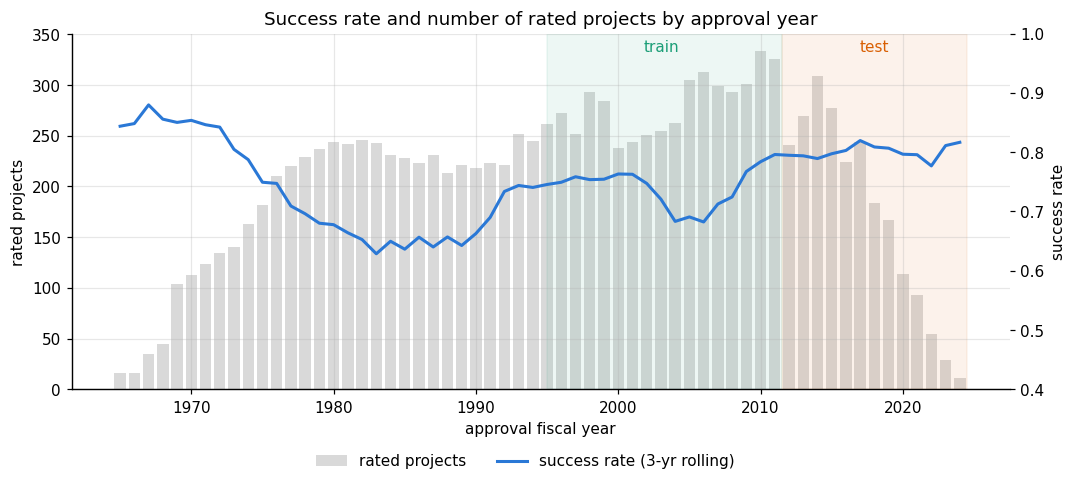

In [3]:
by_year = hist.groupby("approval_fy").agg(n=("label", "size"), success=("label", "mean")).reset_index()
by_year = by_year[by_year.approval_fy.between(1965, 2024)]
fig, ax1 = plt.subplots(figsize=(11, 4.2))
ax1.bar(by_year.approval_fy, by_year.n, color="#d9d9d9", label="rated projects")
ax1.set_ylabel("rated projects"); ax1.set_xlabel("approval fiscal year")
ax2 = ax1.twinx()
ax2.plot(by_year.approval_fy, by_year.success.rolling(3, center=True, min_periods=1).mean(), color=C_ACCENT, lw=2,
         label="success rate (3-yr rolling)")
ax2.set_ylim(0.4, 1.0); ax2.set_ylabel("success rate"); ax2.grid(False)
ax1.axvspan(1995, 2011.5, color=C_SUCCESS, alpha=0.08); ax1.axvspan(2011.5, 2024.5, color=C_FAIL, alpha=0.08)
ax1.text(2003, ax1.get_ylim()[1] * 0.95, "train", ha="center", color=C_SUCCESS)
ax1.text(2018, ax1.get_ylim()[1] * 0.95, "test", ha="center", color=C_FAIL)
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False)
ax1.set_title("Success rate and number of rated projects by approval year")
report.append("## A. Exploratory analysis\n")
save(fig, "a1_success_by_year", "Success rate by approval year (line, 3-year rolling) and number of rated projects (bars). Shaded: train FY1995–2011, test FY2012+.")

### A2. Success rate by region and by sector

**What:** success rate per World Bank region and per major sector (modelled years, FY1995+), with the number of projects in each bar label.

**Why:** big differences between groups explain why region/sector and their *track record* features end up among the strongest predictors.

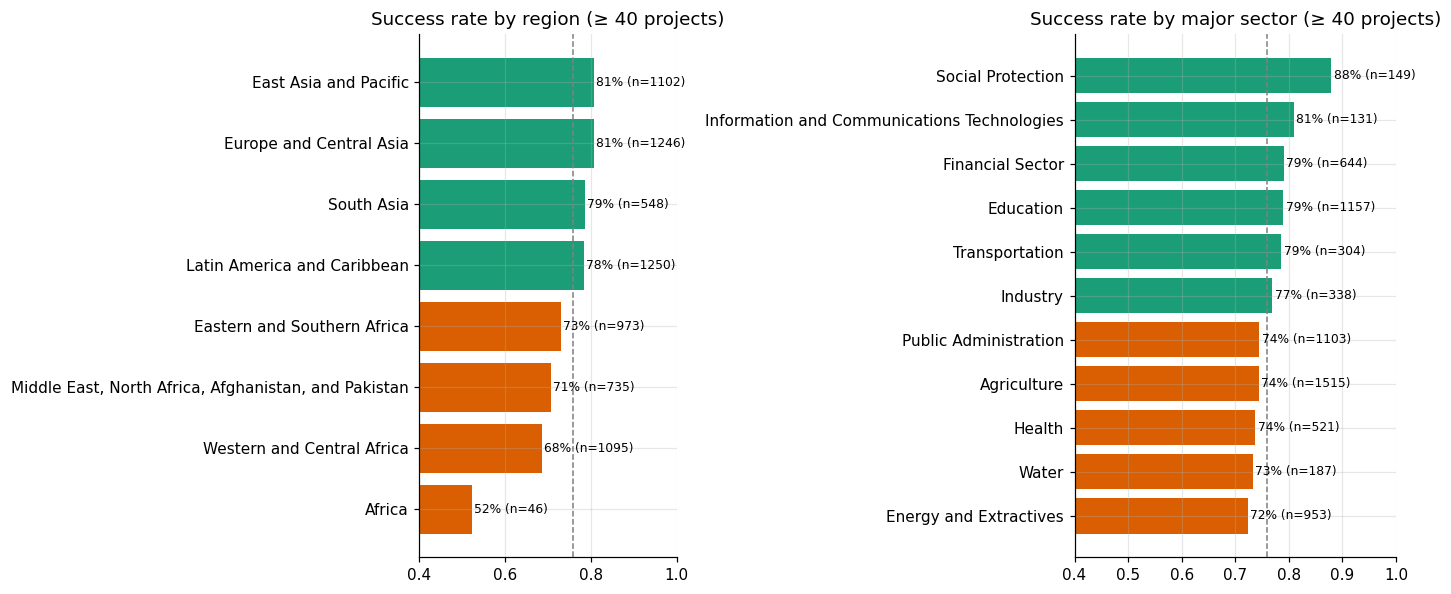

In [4]:
mod = hist[hist.approval_fy >= 1995].assign(major_sector=lambda d: d.major_sector.str.replace("FY17 - ", "", regex=False))
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})
for ax, col, title in [(axes[0], "region", "by region (≥ 40 projects)"), (axes[1], "major_sector", "by major sector (≥ 40 projects)")]:
    g = mod.groupby(col).agg(n=("label", "size"), success=("label", "mean"))
    g = g[g.n >= 40].sort_values("success")
    ax.barh(g.index, g.success, color=[C_FAIL if v < mod.label.mean() else C_SUCCESS for v in g.success])
    ax.axvline(mod.label.mean(), color=C_NEUTRAL, ls="--", lw=1)
    for y, (v, n) in enumerate(zip(g.success, g.n)):
        ax.text(v + 0.005, y, f"{v:.0%} (n={n})", va="center", fontsize=8)
    ax.set_xlim(0.4, 1.0); ax.set_title(f"Success rate {title}")
fig.tight_layout()
save(fig, "a2_success_by_region_sector", "Success rate by region and by major sector, projects approved FY1995+. Dashed line = overall rate.")

### A3. Document coverage

**What:** share of rated projects (per approval year) that have a usable pre-approval document, split by document type.

**Why:** text features only exist where a document exists; it also shows the switch from "Staff Appraisal Reports" to modern "Project Appraisal Documents" around 2000 — a change in document style the model has to cope with.

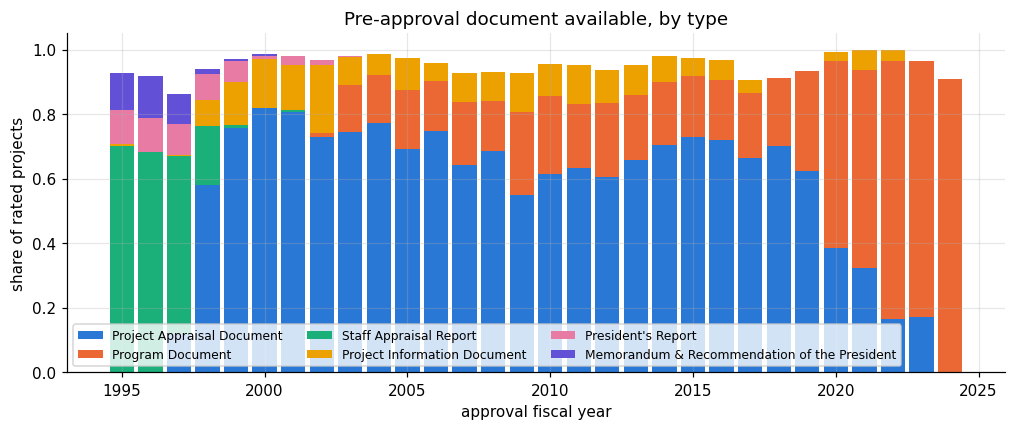

In [5]:
rated_fy = mod.groupby("approval_fy").size()
cov = manifest[manifest.approval_fy >= 1995].groupby(["approval_fy", "doc_type"]).size().unstack(fill_value=0)
cov = cov.reindex(rated_fy.index, fill_value=0).div(rated_fy, axis=0)
order = cov.sum().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(11, 4))
bottom = np.zeros(len(cov))
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
for i, t in enumerate(order):
    ax.bar(cov.index, cov[t], bottom=bottom, color=palette[i % len(palette)], label=t, width=0.85)
    bottom += cov[t].values
ax.set_ylim(0, 1.05); ax.set_ylabel("share of rated projects"); ax.set_xlabel("approval fiscal year")
ax.legend(fontsize=8, ncol=3, loc="lower left"); ax.set_title("Pre-approval document available, by type")
save(fig, "a3_document_coverage", "Share of rated projects with a pre-approval document (dated on/before Board approval), by document type.")

### A4. Missing-data heatmap

**What:** for the main non-one-hot features, the share of projects with a **missing** value, by 4-year approval period.

**Why:** missingness is not random here — governance scores don't exist before 1996, preparation milestones are only recorded for newer projects. XGBoost handles missing values natively, but you need to know *where* they are to interpret the model (and to explain why train and test can behave differently).

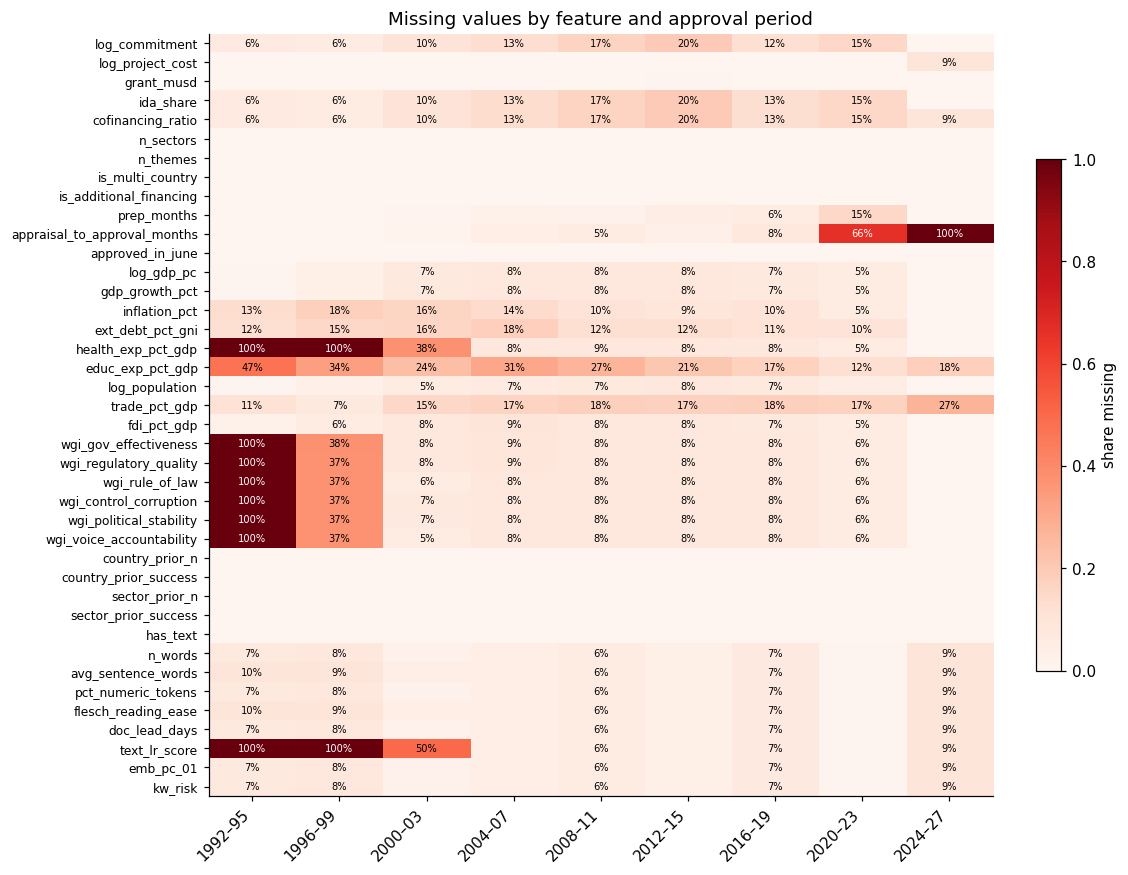

In [6]:
miss_cols = [c for c in STRUCT + TEXT if not is_onehot(c) and not c.startswith(("emb_pc_", "kw_"))] + ["emb_pc_01", "kw_risk"]
labeled["period"] = (labeled.approval_fy // 4 * 4).astype(int).astype(str) + "–" + ((labeled.approval_fy // 4 * 4) + 3).astype(int).astype(str).str[-2:]
miss = labeled.groupby("period")[miss_cols].apply(lambda d: d.isna().mean()).T
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(miss.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(miss.shape[1])); ax.set_xticklabels(miss.columns, rotation=45, ha="right")
ax.set_yticks(range(miss.shape[0])); ax.set_yticklabels(miss.index, fontsize=8)
for i in range(miss.shape[0]):
    for j in range(miss.shape[1]):
        v = miss.values[i, j]
        if v >= 0.05:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=6.5, color="white" if v > 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.03, label="share missing"); ax.grid(False)
ax.set_title("Missing values by feature and approval period")
save(fig, "a4_missing_heatmap", "Share of missing values per feature and 4-year approval period (modelled projects).")

### A5. Correlation heatmap (structured features + label)

**What:** Spearman rank correlation between the main structured features and the label.

**Why:** shows redundancy (e.g. the six governance scores move together; commitment and project cost too) and gives a first, model-free view of which features relate to success. Spearman is used because it captures any monotonic relationship and isn't thrown off by extreme values like very large loans.

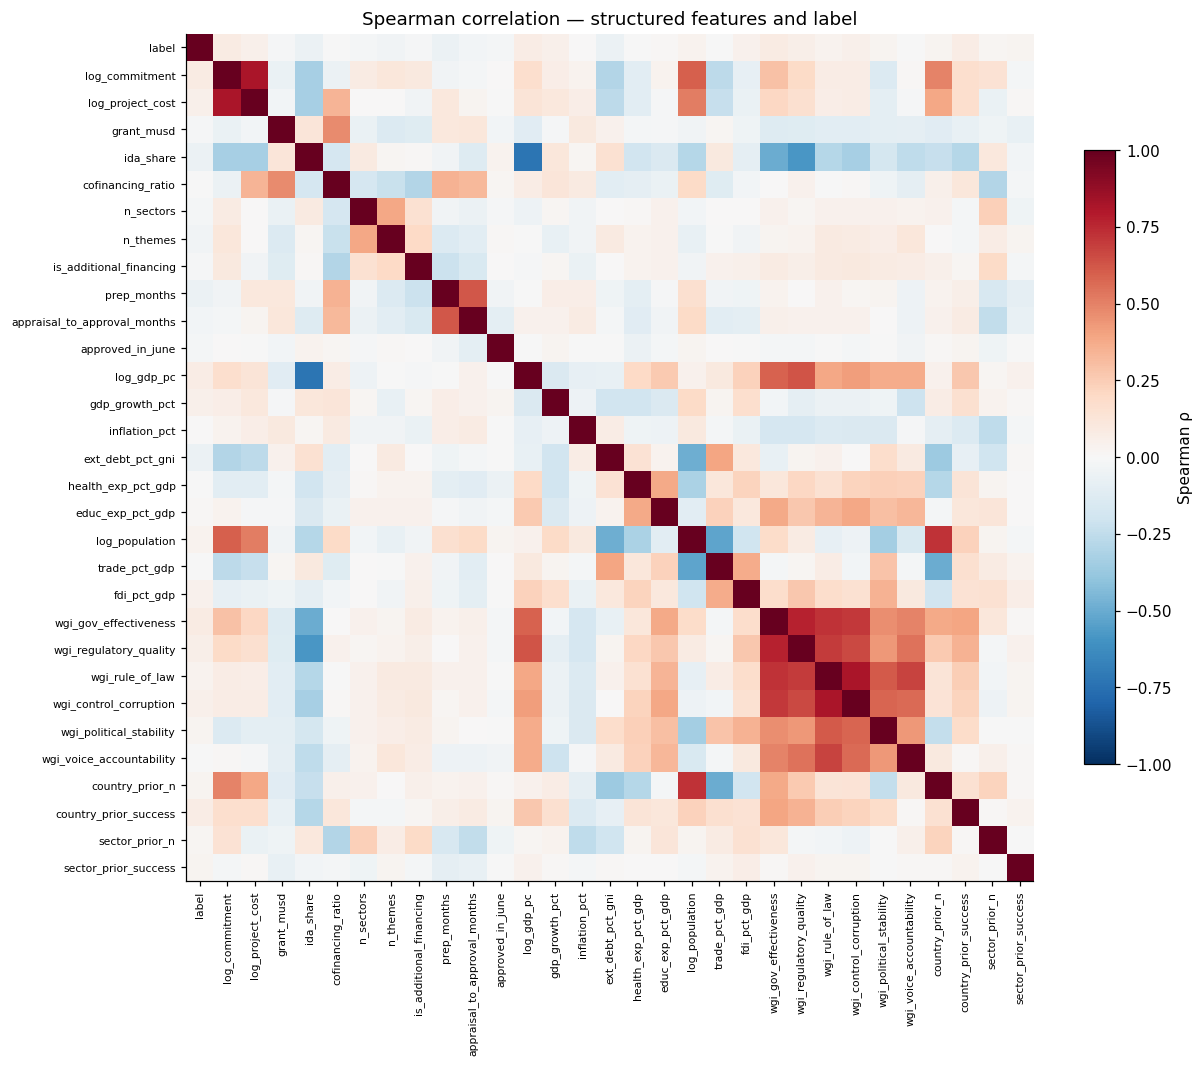

In [7]:
corr_cols = ["label"] + [c for c in STRUCT if not is_onehot(c) and labeled[c].nunique() > 1]   # drop constant columns
corr = labeled[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols))); ax.set_xticklabels(corr_cols, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr_cols))); ax.set_yticklabels(corr_cols, fontsize=7)
fig.colorbar(im, ax=ax, fraction=0.03, label="Spearman ρ"); ax.grid(False)
ax.set_title("Spearman correlation — structured features and label")
save(fig, "a5_correlation_heatmap", "Spearman correlation between structured features and the success label (modelled projects).")

### A6. Which single features separate successes from failures?

**What:** for every numeric feature, the **standardised mean difference** (Cohen's d) between successful and failed projects in the training years — (mean_success − mean_failure) / pooled standard deviation. Top 20 by size, coloured by feature family.

**Why:** a simple, model-free check of signal strength. Values around 0.2 count as a "small" effect; anything much smaller is noise-level. It also shows that structured and text features each carry some signal on their own.

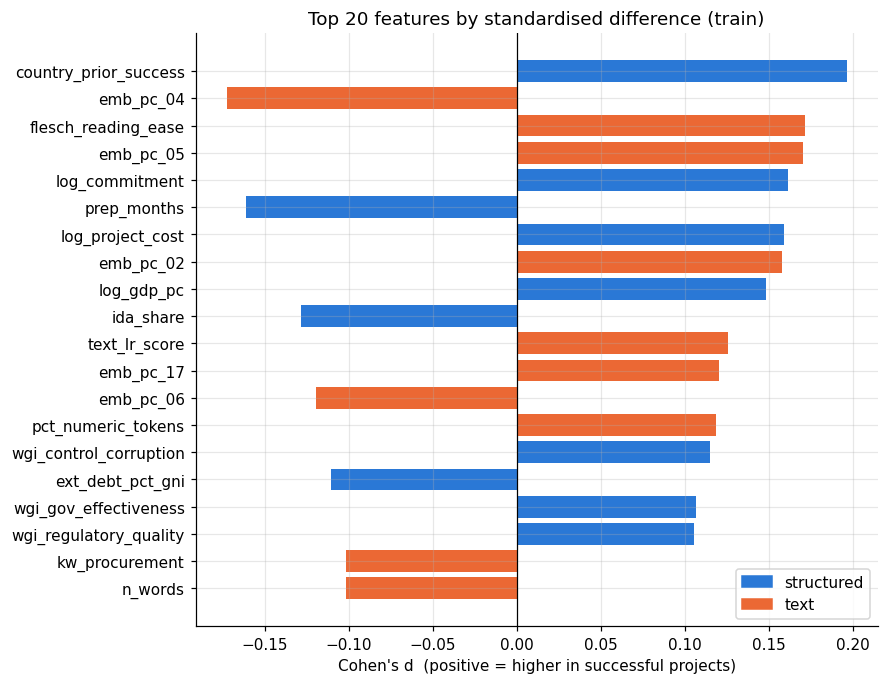

In [8]:
tr = labeled[labeled.split == "train"]
rows = []
for c in [c for c in STRUCT + TEXT if not is_onehot(c)]:
    s, f = tr.loc[tr.label == 1, c].dropna(), tr.loc[tr.label == 0, c].dropna()
    if len(s) > 30 and len(f) > 30:
        pooled = np.sqrt(((len(s) - 1) * s.var() + (len(f) - 1) * f.var()) / (len(s) + len(f) - 2))
        if pooled > 0:
            rows.append((c, (s.mean() - f.mean()) / pooled, "structured" if c in STRUCT else "text"))
eff = pd.DataFrame(rows, columns=["feature", "cohens_d", "group"]).assign(abs_d=lambda d: d.cohens_d.abs())
top = eff.sort_values("abs_d", ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.feature, top.cohens_d, color=[SET_COLORS[g] for g in top.group])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Cohen's d  (positive = higher in successful projects)")
ax.set_title("Top 20 features by standardised difference (train)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=SET_COLORS[g]) for g in ["structured", "text"]],
          labels=["structured", "text"], loc="lower right")
save(fig, "a6_effect_sizes", "Standardised mean difference (Cohen's d) between successful and failed projects, training years.")

### A7. Text features: successes vs failures

**What:** distributions of four interpretable text features for successful vs failed projects (training years): mentions of weak capacity, mentions of reform, "lessons learned" language (all per 1,000 words), and reading ease.

**Why:** makes the text signal concrete — e.g. whether projects that talk a lot about reform or weak capacity fail more often.

/root/.ipykernel/15746/command-4799006755710582-1462957089:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([d.clip(upper=hi) for d in data], labels=["success", "failure"], showfliers=False, patch_artist=True)
/root/.ipykernel/15746/command-4799006755710582-1462957089:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([d.clip(upper=hi) for d in data], labels=["success", "failure"], showfliers=False, patch_artist=True)
/root/.ipykernel/15746/command-4799006755710582-1462957089:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([d.clip(upper=hi) for d in data], labels=["succes

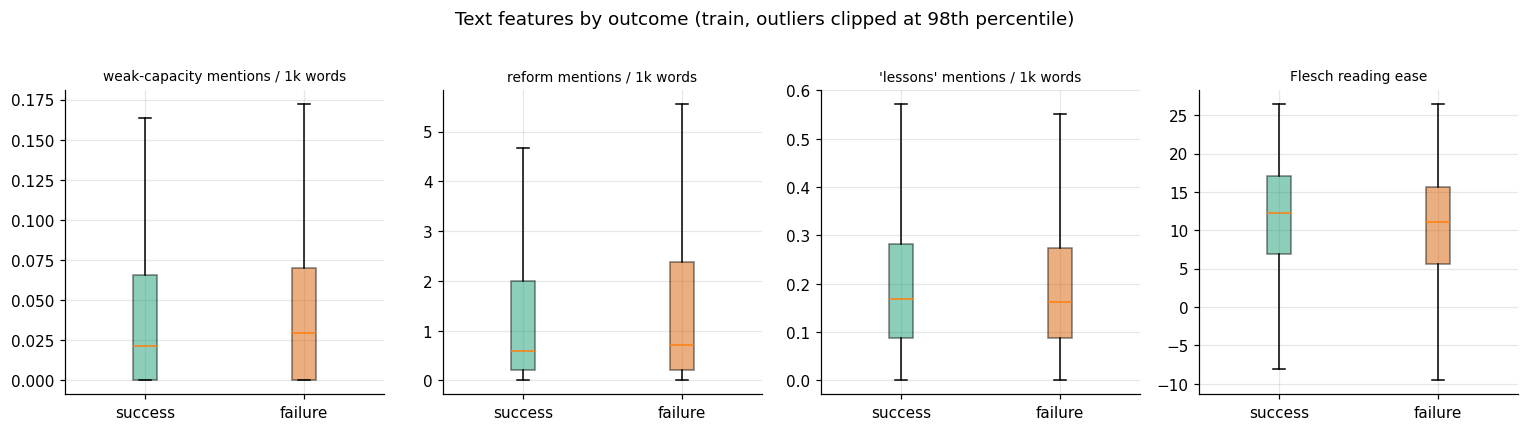

In [9]:
text_show = [("kw_capacity", "weak-capacity mentions / 1k words"), ("kw_reform", "reform mentions / 1k words"),
             ("kw_lessons", "'lessons' mentions / 1k words"), ("flesch_reading_ease", "Flesch reading ease")]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (c, lab) in zip(axes, text_show):
    data = [tr.loc[tr.label == 1, c].dropna(), tr.loc[tr.label == 0, c].dropna()]
    hi = np.nanpercentile(pd.concat(data), 98)
    bp = ax.boxplot([d.clip(upper=hi) for d in data], labels=["success", "failure"], showfliers=False, patch_artist=True)
    for patch, col in zip(bp["boxes"], [C_SUCCESS, C_FAIL]):
        patch.set_facecolor(col); patch.set_alpha(0.5)
    ax.set_title(lab, fontsize=9)
fig.suptitle("Text features by outcome (train, outliers clipped at 98th percentile)", y=1.02)
fig.tight_layout()
save(fig, "a7_text_features_by_outcome", "Selected text features for successful vs failed projects (training years).")

# Part B — Model results

### B1. Model comparison (test set, FY2012+)

**What:** test AUC with 95% bootstrap intervals and PR-AUC on failures for the three feature sets, plus the paired-bootstrap gains.

**Why:** the headline ablation. Overlapping intervals and a paired gain whose interval includes 0 mean "no real difference".

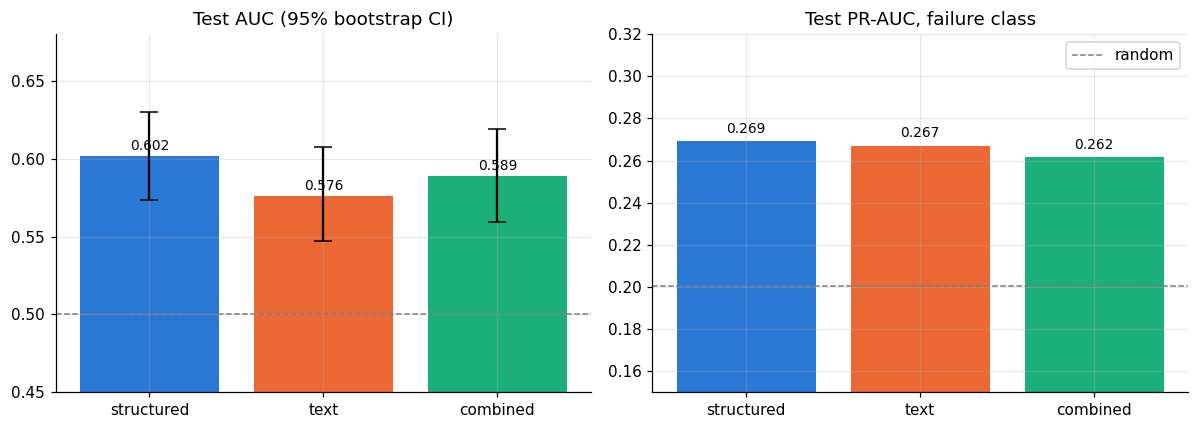

In [10]:
comp = comp.set_index("feature_set").loc[["structured", "text", "combined"]].reset_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(3)
axes[0].bar(x, comp.test_auc, color=[SET_COLORS[s] for s in comp.feature_set],
            yerr=[comp.test_auc - comp.auc_ci_low, comp.auc_ci_high - comp.test_auc], capsize=6)
axes[0].axhline(0.5, color=C_NEUTRAL, ls="--", lw=1); axes[0].set_ylim(0.45, 0.68)
axes[0].set_xticks(x); axes[0].set_xticklabels(comp.feature_set); axes[0].set_title("Test AUC (95% bootstrap CI)")
axes[1].bar(x, comp.pr_auc_failure, color=[SET_COLORS[s] for s in comp.feature_set])
axes[1].axhline(comp.pr_auc_random_baseline.iloc[0], color=C_NEUTRAL, ls="--", lw=1, label="random")
axes[1].set_ylim(0.15, 0.32); axes[1].set_xticks(x); axes[1].set_xticklabels(comp.feature_set)
axes[1].set_title("Test PR-AUC, failure class"); axes[1].legend()
for ax, col in [(axes[0], "test_auc"), (axes[1], "pr_auc_failure")]:
    for i, v in enumerate(comp[col]):
        ax.text(i, v + 0.004, f"{v:.3f}", ha="center", fontsize=9)
fig.tight_layout()
report.append("## B. Model results\n")
report.append(md_table(comp[["feature_set", "val_auc", "test_auc", "auc_ci_low", "auc_ci_high", "pr_auc_failure",
                             "pr_auc_random_baseline", "brier"]]))
report.append("Paired bootstrap (2,000 resamples of the test set):\n\n" + md_table(gains))
save(fig, "b1_model_comparison", "Test AUC with 95% bootstrap intervals and PR-AUC for the failure class, by feature set.")

### B2. ROC and precision-recall curves

**What:** ROC curve (success class) and precision-recall curve (failure class) for each feature set on test.

**Why:** a single AUC hides *where* a model is better; the left end of the PR curve is what matters for "review the riskiest few projects first".

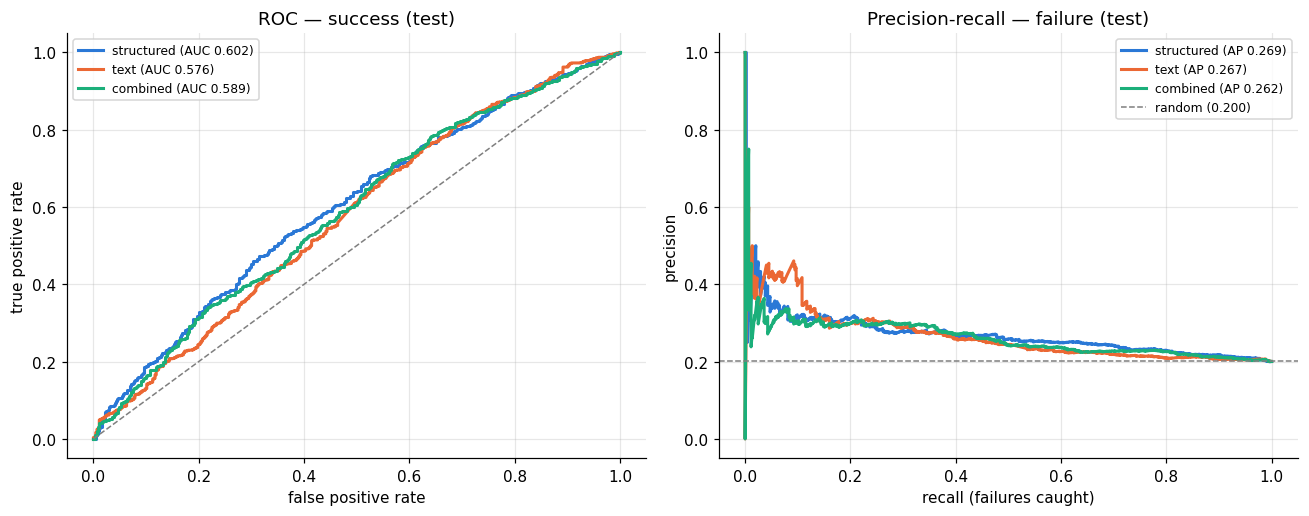

In [11]:
wide = preds.pivot_table(index=["project_id", "label"], columns="feature_set", values="prob_success").reset_index()
y = wide["label"].values
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for fs in ["structured", "text", "combined"]:
    p = wide[fs].values
    fpr, tpr, _ = roc_curve(y, p)
    axes[0].plot(fpr, tpr, color=SET_COLORS[fs], lw=2, label=f"{fs} (AUC {roc_auc_score(y, p):.3f})")
    prec, rec, _ = precision_recall_curve(1 - y, 1 - p)
    axes[1].plot(rec, prec, color=SET_COLORS[fs], lw=2, label=f"{fs} (AP {average_precision_score(1 - y, 1 - p):.3f})")
axes[0].plot([0, 1], [0, 1], color=C_NEUTRAL, ls="--", lw=1)
axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC — success (test)")
axes[1].axhline((1 - y).mean(), color=C_NEUTRAL, ls="--", lw=1, label=f"random ({(1 - y).mean():.3f})")
axes[1].set(xlabel="recall (failures caught)", ylabel="precision", title="Precision-recall — failure (test)")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
save(fig, "b2_roc_pr_curves", "ROC (success) and precision-recall (failure) curves on the test set.")

### B3. Calibration of the champion

**What:** predicted P(success) vs the actual success rate in 10 equal-size groups of test projects, for the deployed champion.

**Why:** if the model says 70%, about 70% of those projects should succeed. Good calibration means the probabilities can be used directly (e.g. "expected number of failures in this portfolio"), not just the ranking.

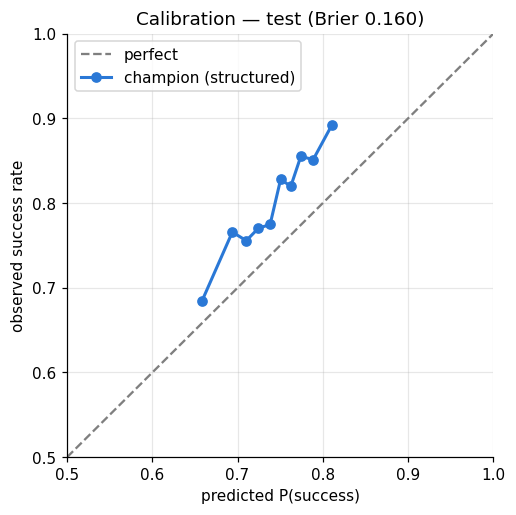

In [12]:
champ = mlflow.MlflowClient().get_model_version_by_alias(MODEL_NAME, "champion")
champ_fs = champ.tags.get("feature_set", "structured")
p_ch = wide[champ_fs].values
frac, mean_pred = calibration_curve(y, p_ch, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0.5, 1], [0.5, 1], "--", color=C_NEUTRAL, label="perfect")
ax.plot(mean_pred, frac, "o-", color=SET_COLORS[champ_fs], lw=2, label=f"champion ({champ_fs})")
ax.set(xlabel="predicted P(success)", ylabel="observed success rate", xlim=(0.5, 1), ylim=(0.5, 1),
       title=f"Calibration — test (Brier {brier_score_loss(y, p_ch):.3f})")
ax.legend()
save(fig, "b3_calibration", f"Calibration of the champion model (v{champ.version}, {champ_fs}) on the test set, 10 quantile bins.")

### B4. Does the risk ranking work? (failure rate by risk decile)

**What:** sorts test projects by the champion's predicted risk of failure into 10 equal groups and plots the actual failure rate in each, against the overall rate.

**Why:** this is the practical test. If the riskiest 10–20% fail clearly more often than average, the ranked list is useful for deciding which projects get extra attention — even with a modest AUC.

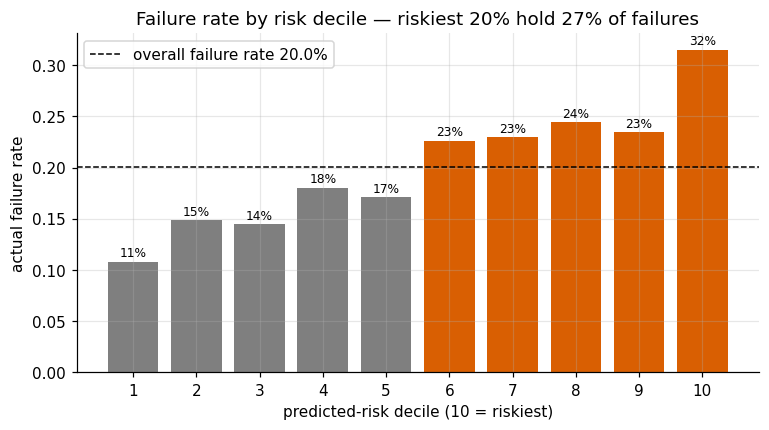

In [13]:
dec = pd.DataFrame({"risk": 1 - p_ch, "fail": 1 - y})
dec["decile"] = pd.qcut(dec.risk.rank(method="first"), 10, labels=range(1, 11))
d = dec.groupby("decile", observed=True).fail.agg(["mean", "size"])
base = dec.fail.mean()
top20 = dec[dec.decile.astype(int) >= 9]
capture = top20.fail.sum() / dec.fail.sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(d.index.astype(int), d["mean"], color=[C_FAIL if v > base else C_NEUTRAL for v in d["mean"]])
ax.axhline(base, color="black", ls="--", lw=1, label=f"overall failure rate {base:.1%}")
for i, v in zip(d.index.astype(int), d["mean"]):
    ax.text(i, v + 0.005, f"{v:.0%}", ha="center", fontsize=8)
ax.set(xlabel="predicted-risk decile (10 = riskiest)", ylabel="actual failure rate",
       title=f"Failure rate by risk decile — riskiest 20% hold {capture:.0%} of failures")
ax.set_xticks(range(1, 11)); ax.legend()
lift = top20.fail.mean() / base
report.append(f"**Risk ranking:** the riskiest 20% of test projects fail at {top20.fail.mean():.1%} vs {base:.1%} overall "
              f"(lift {lift:.2f}×) and contain {capture:.0%} of all failures.\n")
save(fig, "b4_risk_deciles", "Actual failure rate by champion-predicted risk decile on the test set.")

### B5. What drives the predictions? (SHAP)

**What:** mean absolute SHAP value per feature on test, for the champion and for the combined model. SHAP splits each prediction into "how much did each feature push it up or down"; the average size of that push ranks feature importance.

**Why:** explains the model in plain terms and checks it makes sense (e.g. track record and preparation time matter; nothing suspicious like an ID or a post-approval date sneaking in).

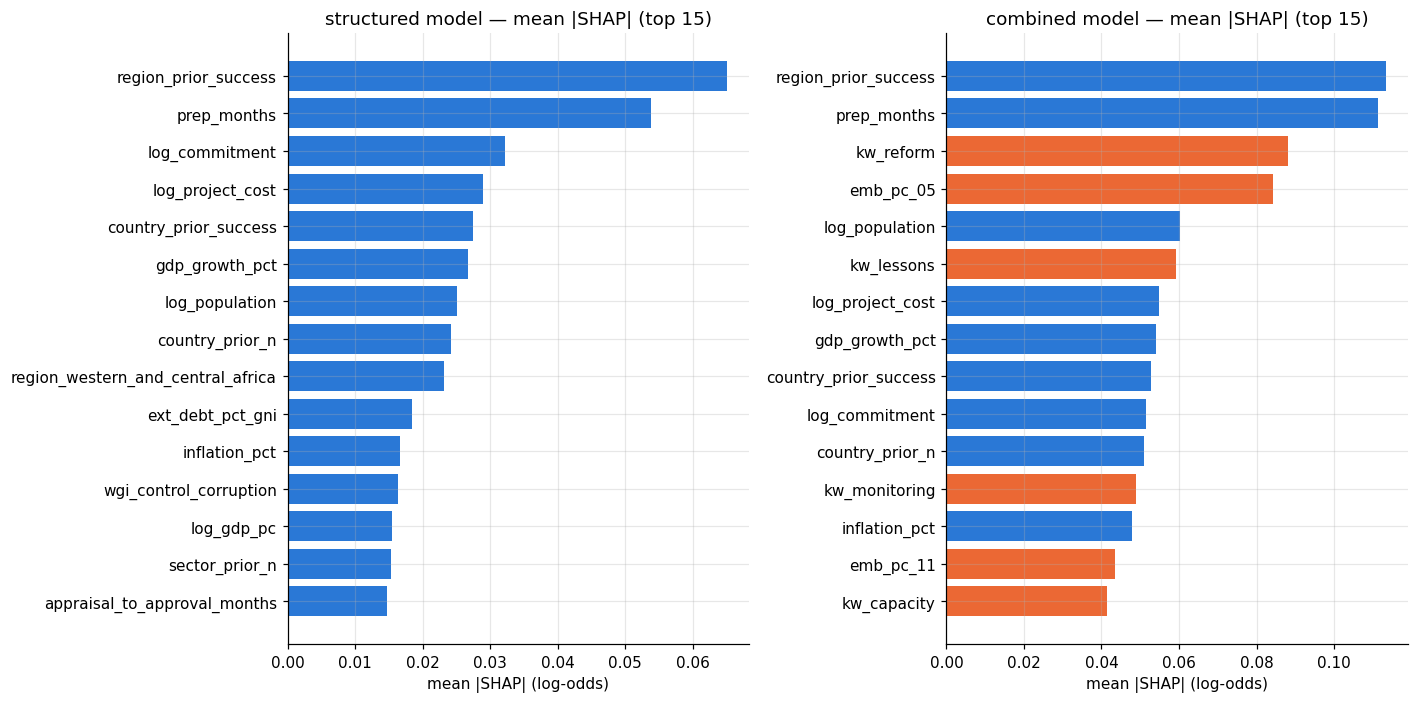

In [14]:
import xgboost as xgb

runs = mlflow.search_runs(experiment_names=[EXPERIMENT], filter_string="tags.stage = 'ablation'", order_by=["start_time DESC"])
if "tags.mlflow.parentRunId" in runs:
    runs = runs[runs["tags.mlflow.parentRunId"].isna()]
runs = runs.drop_duplicates("tags.feature_set").set_index("tags.feature_set")
test = gold[gold.split == "test"]

def shap_importance(fs):
    ens = mlflow.pyfunc.load_model(runs.loc[fs, "tags.model_uri"]).unwrap_python_model()
    dm = xgb.DMatrix(test[ens.features].astype("float64"))
    contrib = np.mean([m.get_booster().predict(dm, pred_contribs=True)[:, :-1] for m in ens.models], axis=0)
    return pd.Series(np.abs(contrib).mean(axis=0), index=ens.features).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, fs in zip(axes, [champ_fs, "combined" if champ_fs != "combined" else "structured"]):
    imp = shap_importance(fs).head(15)[::-1]
    ax.barh(imp.index, imp.values, color=[SET_COLORS["structured"] if f in STRUCT else SET_COLORS["text"] for f in imp.index])
    ax.set_title(f"{fs} model — mean |SHAP| (top 15)"); ax.set_xlabel("mean |SHAP| (log-odds)")
fig.tight_layout()
save(fig, "b5_shap_importance", "Mean absolute SHAP value per feature on test (blue = structured, orange = text).")

### B6. Which words go with success or failure? (TF-IDF model)

**What:** refits the same TF-IDF + logistic-regression text model used in `04_gold_features` on the training documents and plots the 20 words/phrases with the strongest positive and negative weights.

**Why:** the most human-readable view of the text signal. Expect a mix of genuine design signals (institutional reform vs concrete infrastructure) and country/topic words — which is exactly why text overlaps with the structured region/sector features.

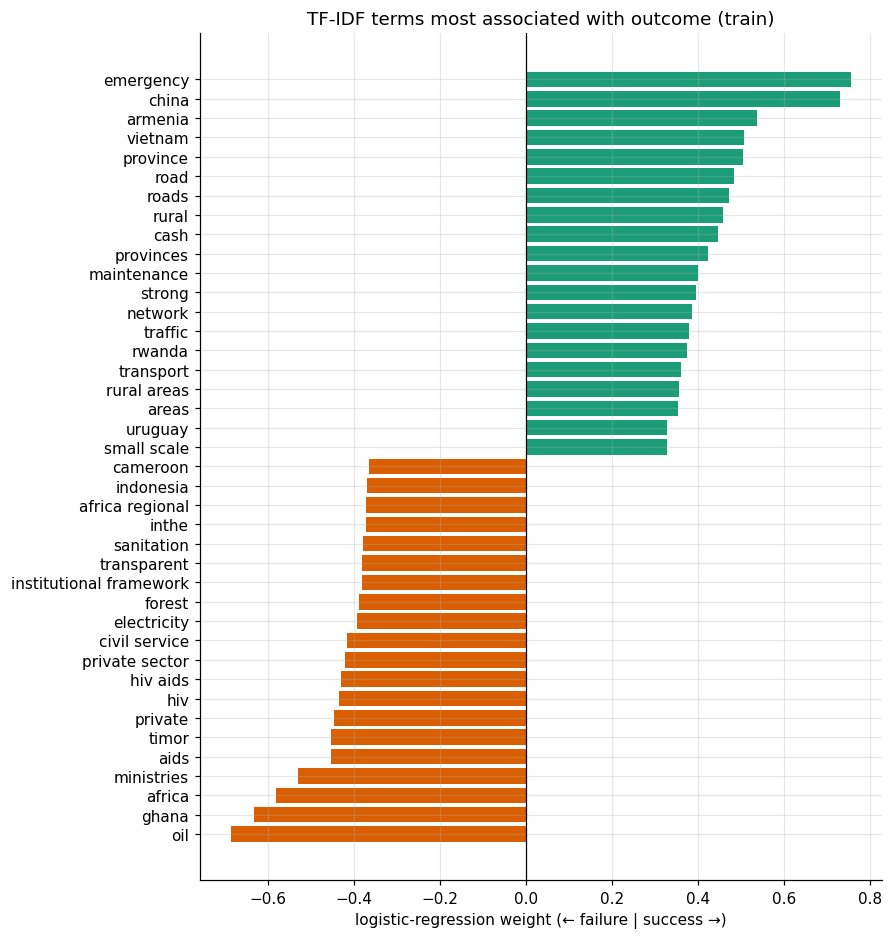

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

docs = (spark.table(f"{CATALOG}.silver.doc_chunks").groupBy("project_id")
        .agg(F.concat_ws(" ", F.sort_array(F.collect_list(F.struct("chunk_idx", "chunk_text"))).getField("chunk_text")).alias("text"))
        .toPandas())
trd = tr.merge(docs, on="project_id")
vec = TfidfVectorizer(min_df=5, max_df=0.9, ngram_range=(1, 2), max_features=50000, sublinear_tf=True, stop_words="english")
lr = LogisticRegression(C=0.5, max_iter=3000).fit(vec.fit_transform(trd.text), trd.label.astype(int))
terms, coef = np.array(vec.get_feature_names_out()), lr.coef_[0]
idx = np.r_[np.argsort(coef)[:20], np.argsort(coef)[-20:]]
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(terms[idx], coef[idx], color=[C_FAIL if c < 0 else C_SUCCESS for c in coef[idx]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("logistic-regression weight (← failure | success →)"); ax.set_title("TF-IDF terms most associated with outcome (train)")
save(fig, "b6_tfidf_terms", "Words and phrases with the largest TF-IDF logistic-regression weights (training documents).")

# Part C — Deployed model on active projects

### C1. Where are the high-risk active projects?

**What:** distribution of predicted failure risk for the 2,505 active projects, and the share flagged **High** (top 20%) by region.

**Why:** this is the output a portfolio manager would use. It also sanity-checks the scores (no region with absurd values, a sensible spread of risk).

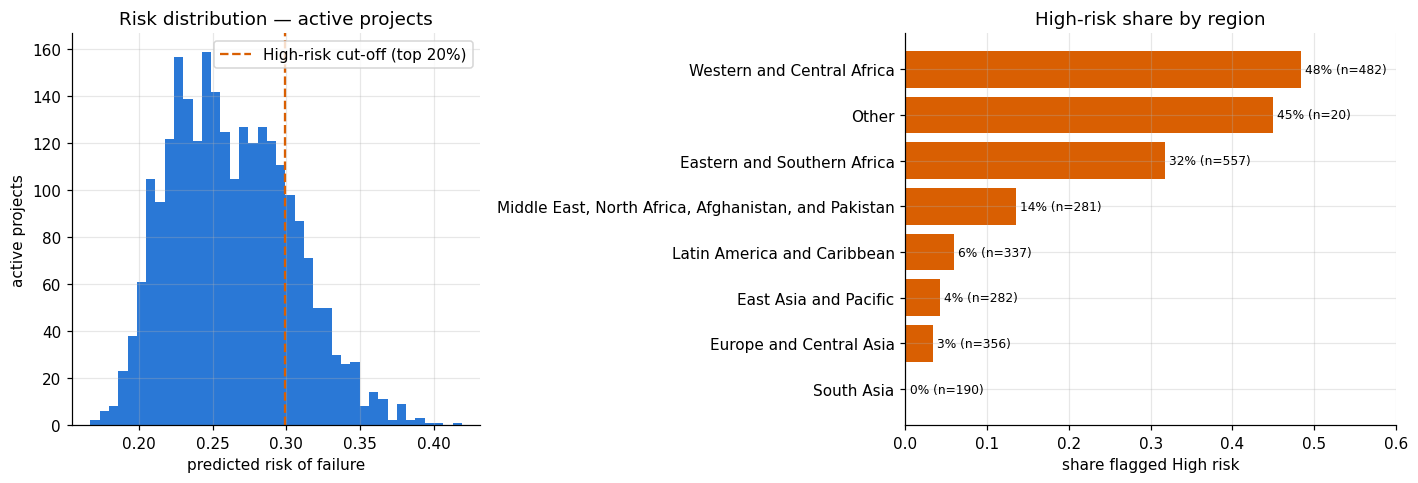

risk_rank,project_id,project_name,country_name,approval_fy,risk_of_failure
1,P177372,Gabon Urban Development Project,Gabon,2025,0.4191
2,P505271,Republic of Congo - Poultry and Aquaculture Development Project,"Congo, Republic of",2027,0.4022
3,P179190,Republic of Congo Strengthening Urban Resilience Project,"Congo, Republic of",2026,0.3985
4,P161877,DRC Transport and Connectivity Support Project,"Congo, Democratic Republic of",2022,0.3938
5,P168772,Valorization of Investments in the Valley of the Logone,Cameroon,2022,0.3906
6,P171658,Bamako Urban Resilience project,Mali,2023,0.3892
7,P172422,Senegal Cadastre and Land Tenure Improvement Project,Senegal,2021,0.3832
8,P171933,Ghana Landscape Restoration and Small-Scale Mining Project,Ghana,2022,0.382
9,P164330,Greater Accra Resilient and Integrated Development Project,Ghana,2019,0.3808
10,P180017,"Cameroon Second Fiscal Sustainability, Inclusive and Sustainable Growth Development Policy Financing",Cameroon,2025,0.3806


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].hist(scores.risk_of_failure, bins=40, color=C_ACCENT)
axes[0].axvline(scores.risk_of_failure.quantile(0.8), color=C_FAIL, ls="--", label="High-risk cut-off (top 20%)")
axes[0].set(xlabel="predicted risk of failure", ylabel="active projects", title="Risk distribution — active projects")
axes[0].legend()
hb = scores.groupby("region").agg(n=("risk_band", "size"), high=("risk_band", lambda s: (s == "High").mean())).sort_values("high")
axes[1].barh(hb.index, hb.high, color=C_FAIL)
for i, (v, n) in enumerate(zip(hb.high, hb.n)):
    axes[1].text(v + 0.005, i, f"{v:.0%} (n={n})", va="center", fontsize=8)
axes[1].set(xlabel="share flagged High risk", title="High-risk share by region"); axes[1].set_xlim(0, max(0.6, hb.high.max() + 0.1))
fig.tight_layout()
report.append("## C. Deployed model on active projects\n")
top10 = scores.sort_values("risk_rank").head(10)[["risk_rank", "project_id", "project_name", "country_name", "approval_fy", "risk_of_failure"]]
report.append("Ten highest-risk active projects (model output, not a judgement on the projects):\n\n" + md_table(top10))
save(fig, "c1_active_risk", "Predicted failure risk for active projects and the share flagged High risk by region.")
display(top10)

## Write the report

**What:** writes all collected Markdown (tables + figure links) to `REPORT.md` in the reports volume and lists the generated files.

**Why:** one self-contained, regenerated-every-run summary that can be copied straight into the GitHub repo.

In [17]:
with open(f"{REPORT_DIR}/REPORT.md", "w", encoding="utf-8") as f:
    f.write("\n".join(report))
files = sorted(os.listdir(FIG_DIR))
print("wrote REPORT.md and", len(files), "figures:", files)
dbutils.notebook.exit(json.dumps({"figures": files, "risk_top20_lift": round(float(lift), 3),
                                  "risk_top20_capture": round(float(capture), 3), "champion": f"v{champ.version} {champ_fs}"}))

{"figures": ["a1_success_by_year.png", "a2_success_by_region_sector.png", "a3_document_coverage.png", "a4_missing_heatmap.png", "a5_correlation_heatmap.png", "a6_effect_sizes.png", "a7_text_features_by_outcome.png", "b1_model_comparison.png", "b2_roc_pr_curves.png", "b3_calibration.png", "b4_risk_deciles.png", "b5_shap_importance.png", "b6_tfidf_terms.png", "c1_active_risk.png"], "risk_top20_lift": 1.372, "risk_top20_capture": 0.275, "champion": "v7 structured"}